# The Virtue of Complexity Everywhere: implementation and results

Team 1: Luwei Cai, Hongjun Ding, Yueqi Lin, Hao Li. Deep Learning in Finance, Assignment 1.

Replication of the equity-factor results of Kelly, Malamud & Zhou (2022), *The Virtue of Complexity Everywhere*, SSRN 4166368, on the paper's own universe of 159 US equity factors, for both of its equity studies (A: 15 Welch-Goyal predictors; B: 2 momentum signals). The main results use the literal eq. 37 features; the eq. 36 kernel is a sensitivity check (Appendix B).

**The paper's idea.** Fit a ridge regression on $L$ random Fourier features of a few return-predicting signals, with $L$ far larger than the training window $T$. Out-of-sample **Sharpe rises with complexity** $c = L/T$ once the ridge penalty $z$ is large enough.

**This notebook** follows the order of the presentation: (1) the model as implemented, with live checks of the code; (2) the data, checked against the paper's Table 1; (3-4) the paper's Figures 1-5 on its 159 equity factors; (5) our feature scaling; (6) what the headline curve does and does not show, using controls the paper does not report (baselines, placebo, exact kernel); (7) a side-by-side summary. The appendices hold a simulator and the eq. 36 vs eq. 37 comparison.

Heavy experiments (about 4 hours in total) are run by `run_all.py` and saved to `figures/*.npz`; this notebook re-plots them. The cells marked **live** run the code here. Line colours follow the paper's figures (dark red $\log_{10}z=-3$ to purple $+3$).

| Section | Content |
|---|---|
| 1 | The model and its implementation (live checks) |
| 2 | Data and preprocessing (checked against the paper's Table 1) |
| 3 | The paper's Figures 1-4 on the 159 factors, $T=12$: 3a momentum signals (Study B), 3b Welch-Goyal predictors (Study A) |
| 4 | The paper's Figure 5: $T=60,120$ |
| 5 | Feature scaling: why we use $1/\sqrt L$, and what other scalings do |
| 6 | Beyond the paper: baselines, placebo, exact kernel |
| 7 | Paper vs. this replication, and what did not work |
| A | Appendix: simulator (do the theory's predictions hold when its assumptions do?) |
| B | Appendix: kernel check, eq. 37 (main) vs eq. 36 |

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from voc import make_rff, rolling_ridge_voc, summarize
from voc.features import GAMMAS
from voc.kernel import mixture_kernel
from voc.simulate import simulate_nonlinear
from voc.preprocess import prepare_factor_dataset
from experiments.curves import PAPER_COLORS   # line colours of the paper's figures, one per log10 z = -3 ... 3

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "figures"
FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
ANN = np.sqrt(12.0)

def nearest(c, values):
    return [int(np.argmin(np.abs(c - v))) for v in values]

def zlabel(z):
    return f"log10 z = {np.log10(z):g}"
print("repo root:", ROOT.name)

repo root: virtue-of-complexity


## 1. The model

**Data-generating assumption (eq. 1).** $R_{t+1} = f(X_t) + \varepsilon_{t+1}$, with $X_t\in\mathbb R^d$ a handful of signals ($d=15$ in Study A, $d=2$ in Study B) and $f$ smooth but unknown.

**Random Fourier features (eqs. 36–37).** The Gaussian-mixture kernel $K(x,y)=\tfrac17\sum_{i=1}^7 e^{-\|x-y\|^2/(2\gamma_i)}$, with $\gamma\in\{0.1,0.5,1,2,4,8,16\}$, is approximated by $\sin(\omega'x),\cos(\omega'x)$ with random frequencies $\omega$ (main runs: the literal eq. 37, frequencies $\gamma\omega$; eq. 36's $\omega/\sqrt\gamma$ is the sensitivity set, Appendix B). Each seed draws $P=7p$ weights $\omega_i\sim N(0,I_d)$, $p$ per bandwidth, and each weight gives a sin and a cos feature. A random permutation removes any ordering, so the first $L$ columns form a nested model of "complexity" $c=L/T$.

**Rolling ridge (eqs. 8–9).** For each date $t$, fit on the $T$ most recent observations:
$$\hat\beta(z)=(zI+\hat\Psi)^{-1}\tfrac1T\sum_\tau S_\tau R_{\tau+1},\qquad \hat\Psi=\tfrac1T\sum_\tau S_\tau S_\tau',\qquad \hat\pi_t=S_t'\hat\beta,$$
and earn the timing return $\hat\pi_t R_{t+1}$.

**Implementation choices.**
* *Dual form.* $\hat\beta=S'(zT\,I+SS')^{-1}y$, so only a $T\times T$ system is solved however large $L$ is. All nested $L$ come from one pass (cumulative Gram matrices over blocks of features).
* *Scaling.* Features are scaled by $1/\sqrt L$, the width of the model being fitted: the standard random-feature normalisation, which makes $FF'/L$ converge to the kernel. The paper writes $P^{-1/2}$ without saying which $P$, so this is our choice; section 5 compares other scalings.
* *No look-ahead.* A forecast at $t$ uses only pairs $(X_\tau, R_{\tau+1})$ for $\tau=t-T,\dots,t-1$; all are known at $t$.

Metrics (eqs. 41–46): out-of-sample $R^2=1-\sum(R-\hat\pi)^2/\sum(R-\bar R)^2$, and the Sharpe ratio of $\hat\pi_tR_{t+1}$.

In [2]:
# LIVE 1a. Random features approximate the exact mixture kernel, with error ~ 1/sqrt(P)
rng = np.random.default_rng(0)
X = rng.standard_normal((40, 2))
K = mixture_kernel(X, X)
ps = [2, 5, 10, 30, 100, 300, 1000, 3000]
errs = []
for p in ps:
    e = []
    for s in range(5):
        F = make_rff(X, p=p, seed=s)
        e.append(np.abs(F @ F.T / (7 * p) - K).max())   # raw features: F F' / P -> K
    errs.append(np.mean(e))
P = 7 * np.array(ps)
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.loglog(P, errs, "o-", label="max |K_hat - K|")
ax.loglog(P, errs[0] * np.sqrt(P[0] / P), "k--", lw=1, label=r"$\propto P^{-1/2}$")
ax.set_xlabel("number of random weights P"); ax.set_ylabel("max abs kernel error"); ax.legend()
ax.set_title("Random features converge to the exact kernel")
plt.show()

/var/folders/yg/wy4j3dxj33z_991wlb79hlvc0000gn/T/ipykernel_64763/3146588092.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [3]:
# LIVE 1b. The dual-form ridge equals the paper's eq. (9) computed literally
rng = np.random.default_rng(0)
N, T = 40, 12
F = rng.standard_normal((N, 60)); y = rng.standard_normal(N)
L_grid, z_grid = [4, 12, 30, 60], [1e-2, 1.0, 100.0]
out = rolling_ridge_voc(F, y, T, L_grid, z_grid, scale="L")

def literal_eq9(t, L, z):
    S = F[t - T:t, :L] / np.sqrt(L); f = F[t, :L] / np.sqrt(L)       # S = F / sqrt(L)
    beta = np.linalg.solve(z * np.eye(L) + S.T @ S / T, S.T @ y[t - T:t] / T)   # eq. (9)
    return f @ beta

worst = 0.0
for i in range(0, len(out["t"]), 4):
    t = out["t"][i]
    for jl, L in enumerate(L_grid):
        for jz, z in enumerate(z_grid):
            worst = max(worst, abs(out["pi"][i, jl, jz] - literal_eq9(t, L, z)))
print(f"max |dual - literal eq.(9)| over {len(L_grid)*len(z_grid)} (L, z) settings and many dates: {worst:.2e}")

max |dual - literal eq.(9)| over 12 (L, z) settings and many dates: 5.77e-15


## 2. Data and preprocessing

The paper's universe is 159 factors: six from Kenneth French's library (`data/fetch_data.py`): Mkt-RF, SMB, HML (from 1926), RMW, CMA (from 1963) and Momentum (from 1927), plus 153 US characteristic factors from jkpfactors.com (capped value-weighted, Jensen-Kelly-Pedersen), all cut at 2021-12. First the six French factors against the paper's Table 1, then all 159.

In [4]:
df = pd.read_csv(ROOT / "data" / "ff_factors_monthly.csv", index_col=0, parse_dates=True)
paper = {"Mom": (7.70, 16.46, .47), "Mkt-RF": (8.29, 18.63, .45), "SMB": (2.39, 11.02, .22),
         "HML": (4.01, 12.29, .33), "RMW": (3.23, 7.71, .42), "CMA": (3.15, 6.90, .46)}
rows = []
for k, (m, v, s) in paper.items():
    r = df[k][:"2021-12"].dropna()
    mm, vv = r.mean() * 1200, r.std() * np.sqrt(12) * 100
    rows.append({"factor": k, "first obs": f"{r.index[0]:%b-%y}", "mean % (ours)": mm, "mean % (paper)": m,
                 "vol % (ours)": vv, "vol % (paper)": v, "SR (ours)": mm / vv, "SR (paper)": s})
display(pd.DataFrame(rows).set_index("factor").round(2))

,first obs,mean % (ours),mean % (paper),vol % (ours),vol % (paper),SR (ours),SR (paper)
factor,,,,,,,
Mom,Jan-27,7.51,7.70,16.35,16.46,0.46,0.47
Mkt-RF,Jul-26,8.33,8.29,18.47,18.63,0.45,0.45
SMB,Jul-26,2.32,2.39,10.94,11.02,0.21,0.22
HML,Jul-26,4.14,4.01,12.23,12.29,0.34,0.33
RMW,Jul-63,3.30,3.23,7.66,7.71,0.43,0.42
CMA,Jul-63,3.13,3.15,6.83,6.90,0.46,0.46


In [5]:
paper_t1 = pd.read_csv(ROOT / "data" / "paper_table1.csv")
from experiments.curves import load_all   # (importing the experiment modules selects the Agg backend)
%matplotlib inline
U = load_all()
rows = [(f, U[f].mean() / U[f].std() * np.sqrt(12), s, U[f].mean() * 1200, m, U[f].std() * np.sqrt(12) * 100, v)
        for f, s, m, v in zip(paper_t1.factor, paper_t1.sharpe, paper_t1.mean_pct, paper_t1.vol_pct) if f in U]
t1 = pd.DataFrame(rows, columns=["factor", "SR ours", "SR paper", "mean ours", "mean paper", "vol ours", "vol paper"])
print(f"{len(U)} series loaded; {len(t1)} of the paper's {len(paper_t1)} Table-1 rows matched by name (the paper's 'intrinsic value' has no counterpart in the public JKP file)")
print("correlation with the paper's Table 1:", {k: round(float(np.corrcoef(t1[k + ' ours'], t1[k + ' paper'])[0, 1]), 4) for k in ["SR", "mean", "vol"]})
print("max |Sharpe difference|: %.3f; mean difference (ours - paper): %+.3f" % ((t1["SR ours"] - t1["SR paper"]).abs().max(), (t1["SR ours"] - t1["SR paper"]).mean()))

159 series loaded; 158 of the paper's 159 Table-1 rows matched by name (the paper's 'intrinsic value' has no counterpart in the public JKP file)
correlation with the paper's Table 1: {'SR': 0.9972, 'mean': 0.9956, 'vol': 0.9995}
max |Sharpe difference|: 0.117; mean difference (ours - paper): +0.010


**Preprocessing (eqs. 13–16), all past-only.** The target is the next-month return divided by a trailing 12-month volatility, $y_t=r_{t+1}/\sigma_t$. The two signals are the lagged return and the trailing 11-month mean return, each divided by an expanding-window RMS (at least 36 months, data before $t$ only) and clipped at $\pm5$.

In [6]:
r = df["Mom"][:"2021-12"].dropna()
X, y = prepare_factor_dataset(r)
display(pd.concat([X, y], axis=1).head(4).round(3))
display(pd.concat([X, y], axis=1).describe().loc[["count", "mean", "std", "min", "max"]].round(2))

,ret_1m,ret_11m,y
date,,,
1930-12-31,3.304,0.951,-1.808
1931-01-31,-2.669,1.858,-2.014
1931-02-28,-3.078,1.204,1.246
1931-03-31,2.035,0.743,1.339


,ret_1m,ret_11m,y
count,1092.00,1092.00,1092.00
mean,0.12,0.38,0.25
std,0.81,0.79,1.17
min,-5.00,-4.41,-8.58
max,3.93,3.01,5.14


## 3. The paper's Figures 1–4 on the 159 factors ($T=12$)

### 3a. Study B: the 2 momentum signals

Same model and protocol as the paper: random Fourier features of a mixture of 7 Gaussian kernels, rolling ridge with window $T=12$, $z\in10^{-3..3}$, the 2-signal *momentum* specification, equal average over the 159 factors, up to 7,000 features, **100** feature draws (as in the paper), the literal eq. 37 features. Sharpe ratios are annualised ($\times\sqrt{12}$); expected return and volatility are per month. The $c$ axis is logarithmic (the paper's is linear to 50 with a break to 1,000).

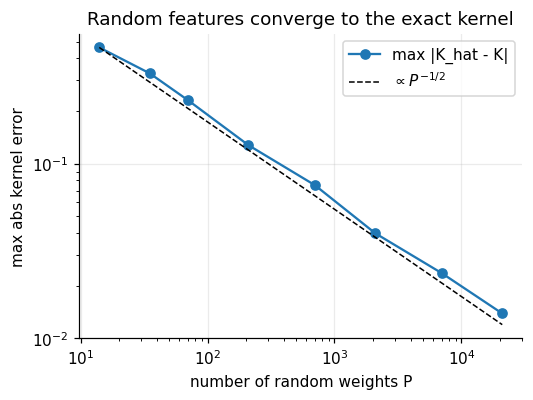

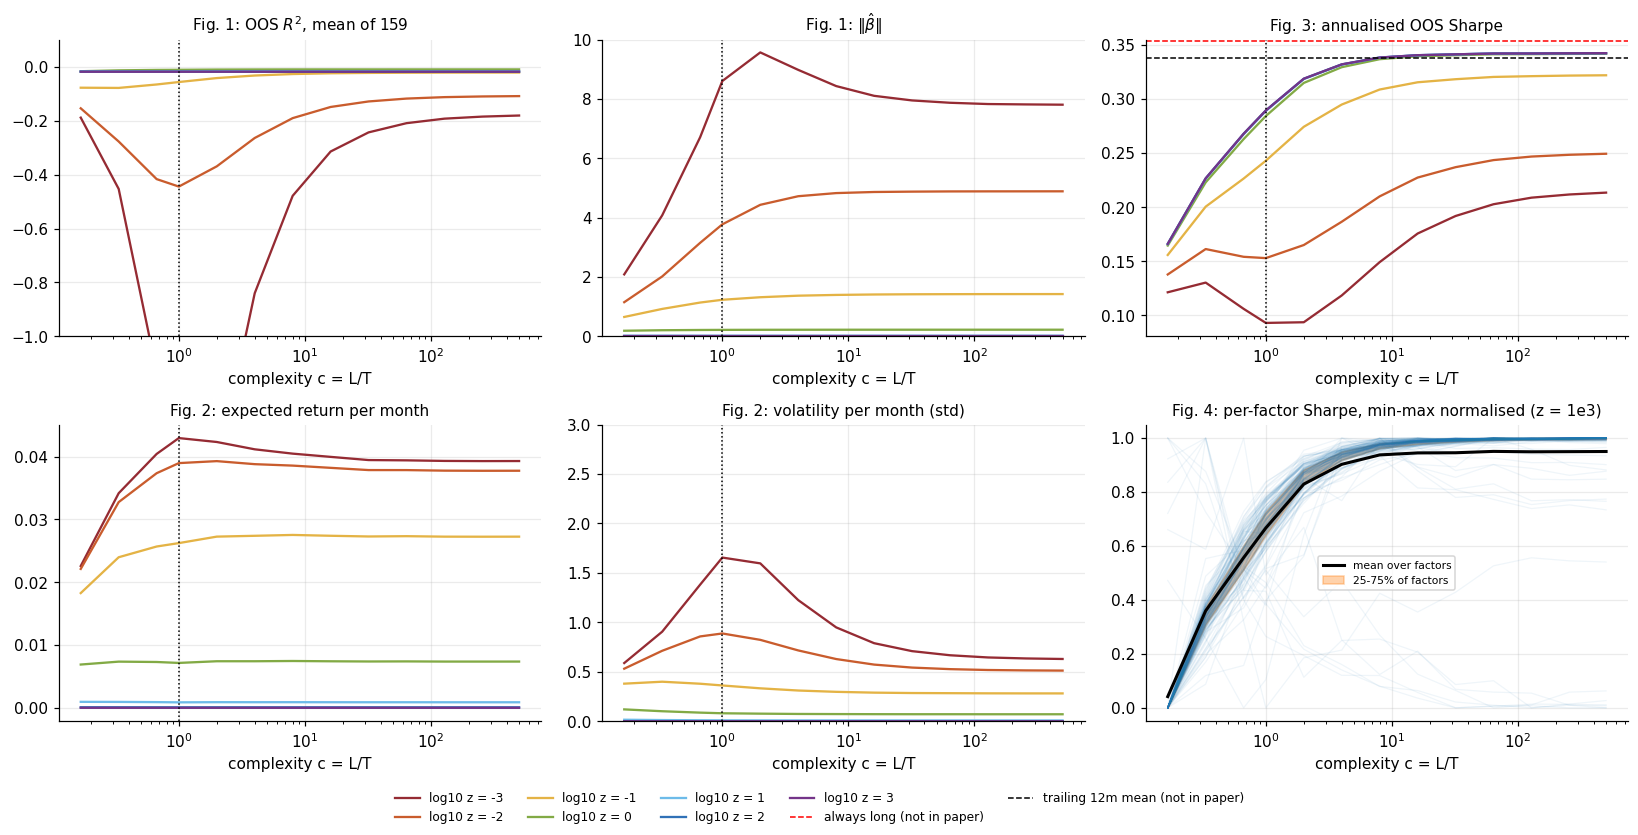

c,0.17,1.00,16.00,500.00
z=1e-3,0.121,0.093,0.176,0.213
z=1e-1,0.156,0.243,0.315,0.322
z=1,0.165,0.284,0.339,0.342
z>=10 (1e3),0.166,0.289,0.340,0.342


In [7]:
d = np.load(FIG / "curves_T12.npz"); names = [str(n) for n in d["names"]]; c, z = d["c"], d["z"]; n = len(names)

def panel(ax, y, title, ylim=None):
    for j, zz in enumerate(z):
        ax.plot(c, y[:, j], color=PAPER_COLORS[j], label=zlabel(zz))
    ax.set_xscale("log"); ax.axvline(1, color="k", ls=":", lw=1); ax.set_title(title, fontsize=10); ax.set_xlabel("complexity c = L/T")
    if ylim: ax.set_ylim(*ylim)

fig, ax = plt.subplots(2, 3, figsize=(15, 7.6))
panel(ax[0, 0], d["R2"].mean(0), f"Fig. 1: OOS $R^2$, mean of {n}", (-1, 0.1))
panel(ax[0, 1], np.sqrt(d["B2"].mean(0)), "Fig. 1: $\\|\\hat\\beta\\|$", (0, 10))
panel(ax[0, 2], d["SR"].mean(0), "Fig. 3: annualised OOS Sharpe")
ax[0, 2].axhline(d["long"].mean(), color="r", ls="--", lw=1, label="always long (not in paper)")
ax[0, 2].axhline(d["trail"].mean(), color="k", ls="--", lw=1, label="trailing 12m mean (not in paper)")
panel(ax[1, 0], d["ER"].mean(0), "Fig. 2: expected return per month")
panel(ax[1, 1], d["Vol"].mean(0), "Fig. 2: volatility per month (std)", (0, 3))
sr = d["SR"][:, :, 6]; nrm = (sr - sr.min(1, keepdims=True)) / (sr.max(1, keepdims=True) - sr.min(1, keepdims=True))
ax[1, 2].plot(c, nrm.T, color="tab:blue", alpha=0.07, lw=0.8); ax[1, 2].plot(c, nrm.mean(0), color="k", lw=2, label="mean over factors")
ax[1, 2].fill_between(c, np.percentile(nrm, 25, 0), np.percentile(nrm, 75, 0), color="tab:orange", alpha=0.35, label="25-75% of factors")
ax[1, 2].set_xscale("log"); ax[1, 2].set_title("Fig. 4: per-factor Sharpe, min-max normalised (z = 1e3)", fontsize=10); ax[1, 2].set_xlabel("complexity c = L/T"); ax[1, 2].legend(fontsize=7)
h, l = ax[0, 2].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.tight_layout(rect=[0, 0.05, 1, 1]); plt.show()

pick = nearest(c, [1 / 6, 1, 16, 500])
display(pd.DataFrame(d["SR"].mean(0)[pick][:, [0, 2, 3, 6]], index=pd.Index(c[pick].round(2), name="c"),
                     columns=["z=1e-3", "z=1e-1", "z=1", "z>=10 (1e3)"]).T.round(3))

In [8]:
paper_er = {1e-3: 0.039, 1e-2: 0.039, 1e-1: 0.039, 1e0: 0.039, 1e1: 0.0375, 1e2: 0.030, 1e3: 0.010}   # Fig. 2 'Momentums' panel at c~1000, by eye
tab = pd.DataFrame({"OOS R2": d["R2"].mean(0)[-1], "||beta||": np.sqrt(d["B2"].mean(0))[-1], "ER / month": d["ER"].mean(0)[-1],
                    "Vol / month": d["Vol"].mean(0)[-1], "paper ER (by eye)": [paper_er[float(zz)] for zz in z]},
                   index=[f"z=1e{int(np.log10(zz)):+d}" for zz in z]).iloc[::-1]
print(f"mean over {n} factors at c = {c[-1]:.0f}; the paper's Vol at c~1000 is about 0.8-0.9 for z<=1e-1")
display(tab.round(4))
dd = d["SR"][:, -1, 6] - d["SR"][:, 0, 6]
print(f"Sharpe at c={c[-1]:.0f} minus c={c[0]:.2f} (z=1e3): {dd.mean():+.3f} (s.e. {dd.std(ddof=1)/np.sqrt(n):.3f}); {np.mean(dd > 0):.0%} of factors positive")
print("minimum of the z=1e-3 curve is at c =", c[int(np.argmin(d['SR'].mean(0)[:, 0]))], "(the paper's dip is near c = 1)")

mean over 159 factors at c = 500; the paper's Vol at c~1000 is about 0.8-0.9 for z<=1e-1


,OOS R2,||beta||,ER / month,Vol / month,paper ER (by eye)
z=1e+3,-0.0187,0.0003,0.0000,0.0001,0.0100
z=1e+2,-0.0186,0.0025,0.0001,0.0009,0.0300
z=1e+1,-0.0174,0.0252,0.0009,0.0086,0.0375
z=1e+0,-0.0101,0.2259,0.0074,0.0712,0.0390
z=1e-1,-0.0218,1.4267,0.0273,0.2820,0.0390
z=1e-2,-0.1092,4.8901,0.0377,0.5127,0.0390
z=1e-3,-0.1811,7.8093,0.0393,0.6302,0.0390


Sharpe at c=500 minus c=0.17 (z=1e3): +0.176 (s.e. 0.009); 96% of factors positive
minimum of the z=1e-3 curve is at c = 1.0 (the paper's dip is near c = 1)


**Reading it, against the paper.**
* **Sharpe (Fig. 3).** It rises with $c$ for large $z$: 0.166 → 0.342, 2.1× against the paper's ≈ 3× (≈ 0.1 → 0.30). 96% of factors improve. The $z=10^{-3}$ curve dips to 0.093 **at $c=1$** (paper ≈ 0.07) and recovers to 0.213 (paper ≈ 0.15).
* **$R^2$ (Fig. 1).** Collapses near $c=1$ for small $z$ (−1.67) while Sharpe stays positive, and recovers to −0.18 at $c=500$ (paper ≈ −0.45).
* **$\|\hat\beta\|$ (Fig. 1).** Partly: it peaks near $c=2$ (9.6) and then falls, to a plateau of 7.8, where the paper's keeps falling towards ≈ 1 (section 5).
* **Expected return and volatility (Fig. 2).** ER matches at low $z$ (0.039 vs ≈ 0.04); Vol is lower (0.63 vs ≈ 0.8–0.9). The paper's ER is still 0.010 at $z=10^3$ and 0.030 at $z=10^2$, where ours is about 0: the paper's $z$ axis sits roughly three decades above ours.
* **Fig. 4.** Most factors rise (92% end above 0.9 of their own range, 4% below 0.5), a few do not.

### 3b. Study A: the 15 Welch-Goyal predictors (the paper's Panel A)

Same model and 159 factors; the signals are the paper's 14 listed predictors (dfy, infl, svar, de, lty, tms, tbl, dfr, dp, dy, ltr, ep, b/m, ntis) plus the market return, built from Amit Goyal's monthly spreadsheet (`data/fetch_data.py --wg`), standardised past-only. 100 feature draws. Paper values (Panel A of its Figs 1-3) are read off by eye: Sharpe ≈ 0.11 → ≈ 0.36 at large $z$; dip to ≈ 0.07 at $c=1$ for $z=10^{-3}$ rising to ≈ 0.29 at $c=50$ and ≈ 0.32 at $c=1000$; ER ≈ 0.041; Vol ≈ 0.45 at $c=1000$; $R^2\approx-0.05$ at $c=50$ for $z=10^{-3}$; $\|\hat\beta\|$ falling to ≈ 1 by $c=50$.

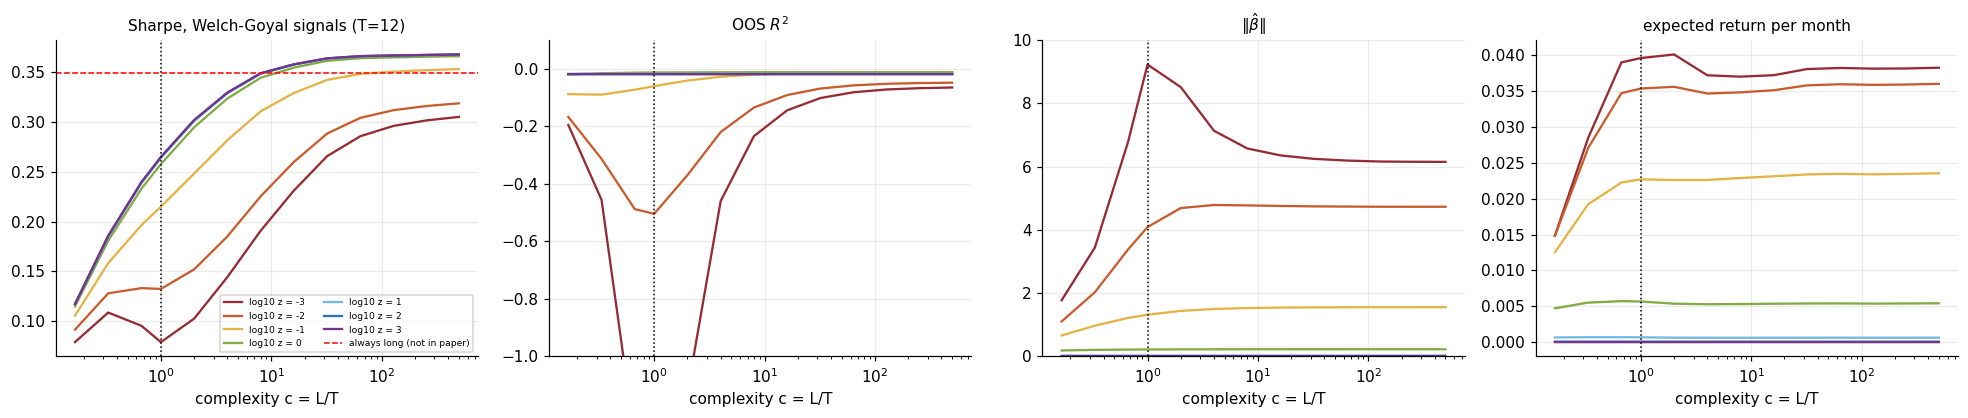

c,0.17,1.00,16.00,500.00
z=1e-3,0.079,0.079,0.231,0.305
z=1e-1,0.106,0.215,0.329,0.353
z=1,0.115,0.258,0.354,0.366
z>=10 (1e3),0.117,0.265,0.358,0.368


Sharpe at c=500 minus c=0.17 (z=1e3): +0.250 (s.e. 0.011); 98% positive; ratio 3.14x
c=500, z=1e-3: ER 0.0382, Vol 0.424, R2 -0.065, ||beta|| 6.15
always long 0.349; trailing 0.355; model minus always long +0.019 (s.e. 0.018)
T=60: Sharpe c_min -> c_max at z=1e3: 0.266 -> 0.335 (+0.069); always long 0.349
T=120: Sharpe c_min -> c_max at z=1e3: 0.296 -> 0.326 (+0.030); always long 0.350


In [9]:
W = {T: np.load(FIG / f"curves_T{T}_wg.npz") for T in (12, 60, 120)}
dw = W[12]; cw, zw = dw["c"], dw["z"]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.9))
panel(ax[0], dw["SR"].mean(0), "Sharpe, Welch-Goyal signals (T=12)")
ax[0].axhline(float(dw["long"].mean()), color="r", ls="--", lw=1, label="always long (not in paper)")
panel(ax[1], dw["R2"].mean(0), "OOS $R^2$", (-1, 0.1))
panel(ax[2], np.sqrt(dw["B2"].mean(0)), "$\\|\\hat\\beta\\|$", (0, 10))
panel(ax[3], dw["ER"].mean(0), "expected return per month")
ax[0].legend(fontsize=6, ncol=2); fig.tight_layout(); plt.show()
pick = nearest(cw, [1 / 6, 1, 16, 500])
display(pd.DataFrame(dw["SR"].mean(0)[pick][:, [0, 2, 3, 6]], index=pd.Index(cw[pick].round(2), name="c"),
                     columns=["z=1e-3", "z=1e-1", "z=1", "z>=10 (1e3)"]).T.round(3))
gw = dw["SR"][:, -1, 6] - dw["SR"][:, 0, 6]; nW = len(gw)
print(f"Sharpe at c={cw[-1]:.0f} minus c={cw[0]:.2f} (z=1e3): {gw.mean():+.3f} (s.e. {gw.std(ddof=1)/np.sqrt(nW):.3f}); {np.mean(gw > 0):.0%} positive; ratio {dw['SR'].mean(0)[-1, 6] / dw['SR'].mean(0)[0, 6]:.2f}x")
print(f"c=500, z=1e-3: ER {dw['ER'].mean(0)[-1, 0]:.4f}, Vol {dw['Vol'].mean(0)[-1, 0]:.3f}, R2 {dw['R2'].mean(0)[-1, 0]:+.3f}, ||beta|| {np.sqrt(dw['B2'].mean(0))[-1, 0]:.2f}")
print(f"always long {dw['long'].mean():.3f}; trailing {dw['trail'].mean():.3f}; model minus always long {(dw['SR'][:, -1, 6] - dw['long']).mean():+.3f} (s.e. {(dw['SR'][:, -1, 6] - dw['long']).std(ddof=1)/np.sqrt(nW):.3f})")
for T in (60, 120):
    g = W[T]["SR"][:, -1, 6] - W[T]["SR"][:, 0, 6]
    print(f"T={T}: Sharpe c_min -> c_max at z=1e3: {W[T]['SR'].mean(0)[0, 6]:.3f} -> {W[T]['SR'].mean(0)[-1, 6]:.3f} ({g.mean():+.3f}); always long {W[T]['long'].mean():.3f}")

**Reading it.** The Welch-Goyal panel is the closer replication: the large-$z$ gain is 3.1× (0.117 → 0.368), the paper's "factor of three"; the $z=10^{-3}$ dip is at $c=1$ (0.079, paper ≈ 0.07) and the curve ends at 0.305 (paper ≈ 0.32); ER (0.038), Vol (0.42) and $R^2$ (−0.065) are close to the paper's. What does not match is $\|\hat\beta\|$ (plateau of 6.1, the paper's falls to ≈ 1) and the $z=1\ldots10$ curves (0.366 at $z=1$ here, ≈ 0.31 in the paper), the same two discrepancies as for momentum (section 5). The model is +0.019 above always long (s.e. 0.018), +0.013 above the trailing mean (s.e. 0.003), so still no clear timing edge.

### 3c. The same figures on the paper's axes

The paper plots $c$ on a **linear** axis from 0 to 50, then a break and a short piece at the far right for its largest model ($c=1000$). The plots below use the same layout: the main panel is linear in $c$ up to 50; the small panel on the right shows our largest model, $c=500$ (we stop at 7,000 features, the paper at 12,000), as a flat segment. Left: Study A (Welch-Goyal); right or below: Study B (momentum). Line colours as in the paper; the dashed vertical line is $c=1$. Our $c$ grid is coarse inside $[0,50]$ (about ten points), so curves are less smooth than the paper's.

In [10]:
# Paper-style axes: linear c up to 50, a break, and a short panel at the far right for the largest model (c = 500 here, 1,000 in the paper)
from matplotlib.gridspec import GridSpec
dB = np.load(FIG / "curves_T12.npz")        # Study B: momentum signals
dA = np.load(FIG / "curves_T12_wg.npz")     # Study A: Welch-Goyal predictors

def broken_panel(fig, spec, c, y, title, ylim=None, ylabel=None, c_end=500):
    """y: (len(c), 7) curves, one per log10 z = -3..3. Left axis: c in [0, 50]; right axis: the value at the largest c."""
    inner = spec.subgridspec(1, 2, width_ratios=[8, 1], wspace=0.08)
    a, b = fig.add_subplot(inner[0]), fig.add_subplot(inner[1], sharey=None)
    for j in range(y.shape[1]):
        a.plot(c, y[:, j], color=PAPER_COLORS[j], lw=1.6)
        b.hlines(y[-1, j], c_end - 10, c_end, color=PAPER_COLORS[j], lw=1.6)
    a.axvline(1, color="gray", ls="--", lw=1)
    a.set_xlim(0, 50); b.set_xlim(c_end - 10, c_end); b.set_xticks([c_end])
    if ylim: a.set_ylim(*ylim)
    b.set_ylim(a.get_ylim()); b.set_yticks([])
    a.spines["right"].set_visible(False); b.spines["left"].set_visible(False)
    a.set_title(title, fontsize=10); a.set_xlabel("c = L/T"); a.grid(False); b.grid(False)
    if ylabel: a.set_ylabel(ylabel)
    d = 0.02   # break marks
    a.plot([1 - d, 1 + d], [-d, d], transform=a.transAxes, color="k", clip_on=False, lw=1)
    b.plot([-d * 6, d * 6], [-d, d], transform=b.transAxes, color="k", clip_on=False, lw=1)
    return a, b

def zlegend(fig, extra=None):
    h = [plt.Line2D([], [], color=PAPER_COLORS[j], lw=1.8) for j in range(7)] + [plt.Line2D([], [], color="gray", ls="--")]
    l = [f"log10(z) = {j - 3}" for j in range(7)] + ["c = 1"]
    fig.legend(h, l, loc="lower center", ncol=8, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 0.0))

studies = [("Panel A: Equities with WG factors", dA), ("Panel B: Equities with Momentums", dB)]


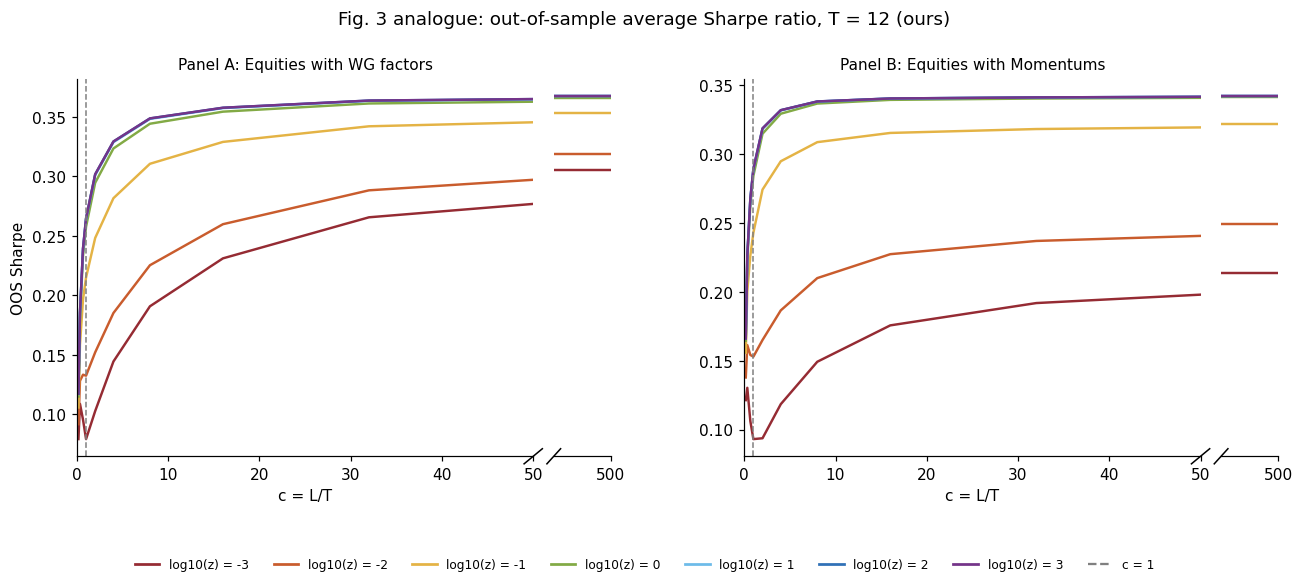

In [11]:
# Fig. 3 on the paper's axes: out-of-sample Sharpe (annualised)
fig = plt.figure(figsize=(12, 5.2)); gs = GridSpec(1, 2, figure=fig, wspace=0.25, bottom=0.22, top=0.88, left=0.07, right=0.98)
for k, (title, dd_) in enumerate(studies):
    broken_panel(fig, gs[k], dd_["c"], dd_["SR"].mean(0), title, ylabel="OOS Sharpe" if k == 0 else None)
zlegend(fig); fig.suptitle("Fig. 3 analogue: out-of-sample average Sharpe ratio, T = 12 (ours)", y=1.0)
plt.show()

/var/folders/yg/wy4j3dxj33z_991wlb79hlvc0000gn/T/ipykernel_64763/993465636.py:7: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.08, 1, 0.97]); plt.show()


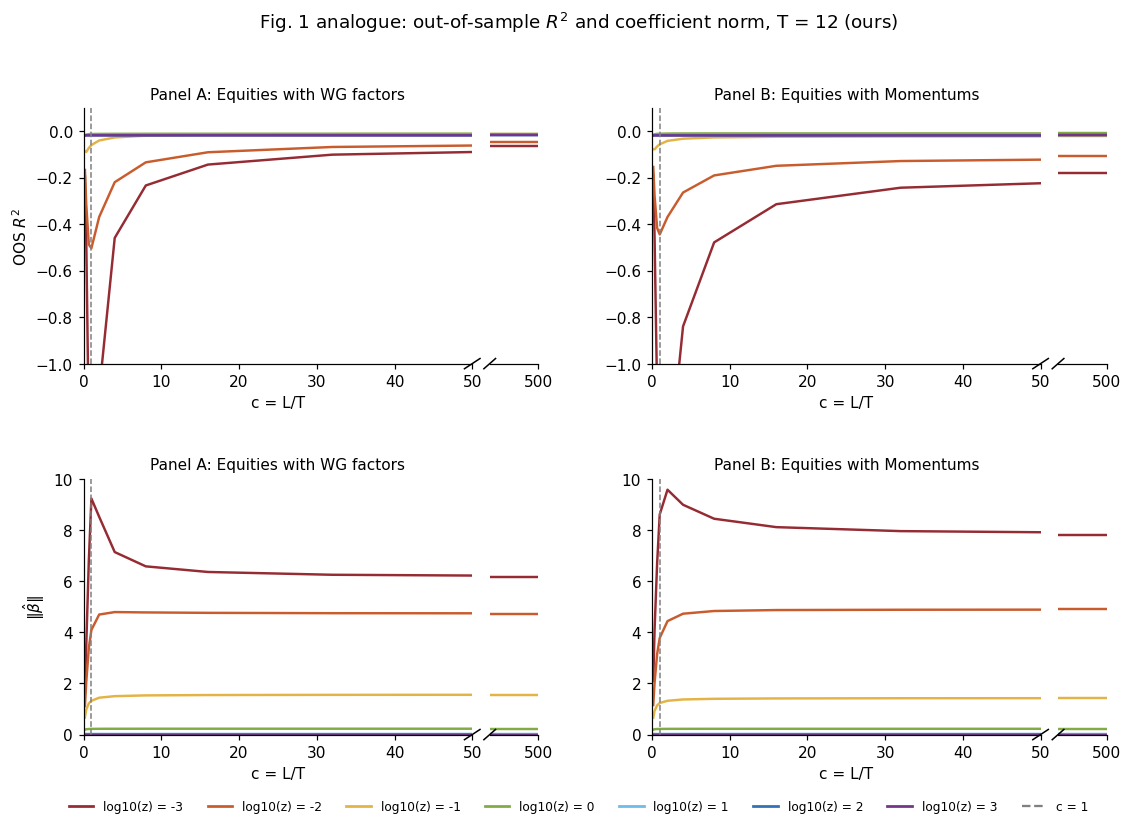

In [12]:
# Fig. 1 on the paper's axes: out-of-sample R^2 (top) and the coefficient norm (bottom)
fig = plt.figure(figsize=(12, 7.4)); gs = GridSpec(2, 2, figure=fig, wspace=0.25, hspace=0.45)
for k, (title, dd_) in enumerate(studies):
    broken_panel(fig, gs[0, k], dd_["c"], dd_["R2"].mean(0), title, ylim=(-1, 0.1), ylabel="OOS $R^2$" if k == 0 else None)
    broken_panel(fig, gs[1, k], dd_["c"], np.sqrt(dd_["B2"].mean(0)), title, ylim=(0, 10), ylabel=r"$\|\hat\beta\|$" if k == 0 else None)
zlegend(fig); fig.suptitle("Fig. 1 analogue: out-of-sample $R^2$ and coefficient norm, T = 12 (ours)", y=1.0)
fig.tight_layout(rect=[0, 0.08, 1, 0.97]); plt.show()

/var/folders/yg/wy4j3dxj33z_991wlb79hlvc0000gn/T/ipykernel_64763/16285600.py:7: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.08, 1, 0.97]); plt.show()


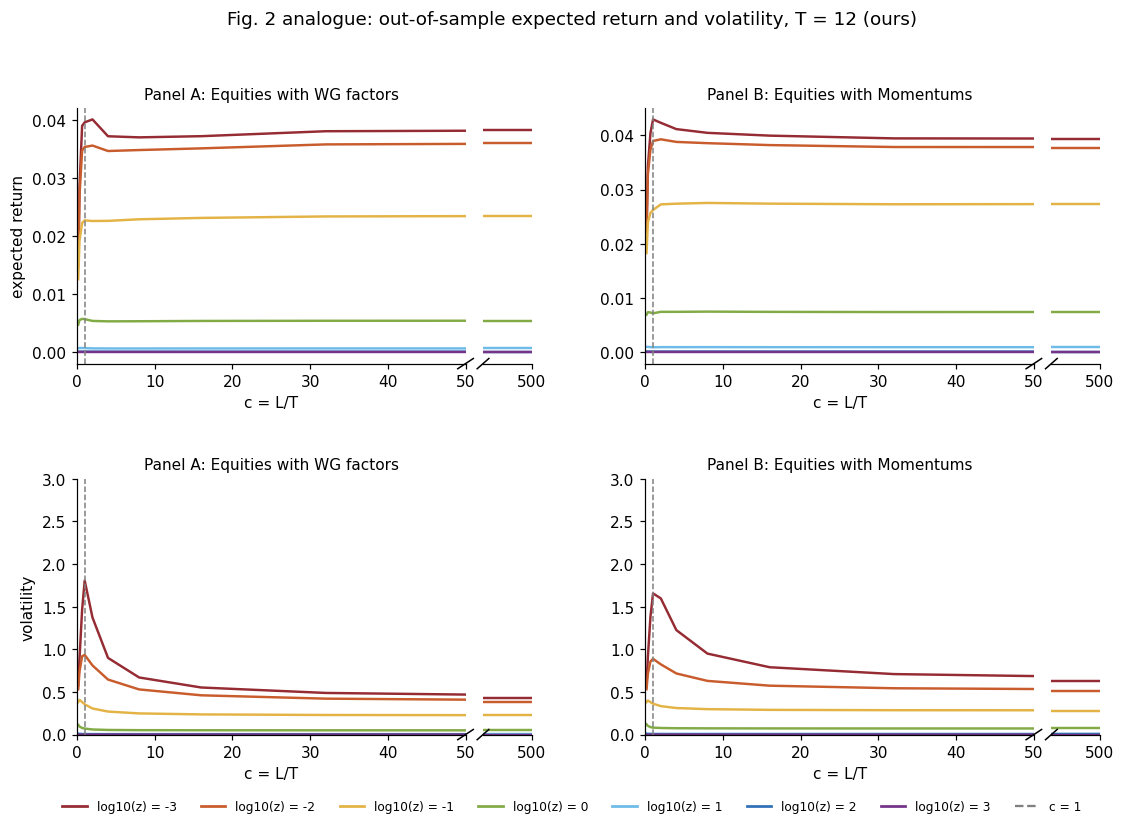

In [13]:
# Fig. 2 on the paper's axes: expected return (top) and volatility (bottom), per month
fig = plt.figure(figsize=(12, 7.4)); gs = GridSpec(2, 2, figure=fig, wspace=0.25, hspace=0.45)
for k, (title, dd_) in enumerate(studies):
    broken_panel(fig, gs[0, k], dd_["c"], dd_["ER"].mean(0), title, ylabel="expected return" if k == 0 else None)
    broken_panel(fig, gs[1, k], dd_["c"], dd_["Vol"].mean(0), title, ylim=(0, 3), ylabel="volatility" if k == 0 else None)
zlegend(fig); fig.suptitle("Fig. 2 analogue: out-of-sample expected return and volatility, T = 12 (ours)", y=1.0)
fig.tight_layout(rect=[0, 0.08, 1, 0.97]); plt.show()

## 4. The paper's Figure 5: longer training windows

$T=60$ and $T=120$ on the same 159 factors, 10 feature draws, up to 7,000 features (so $c\le64$ and $c\le32$).

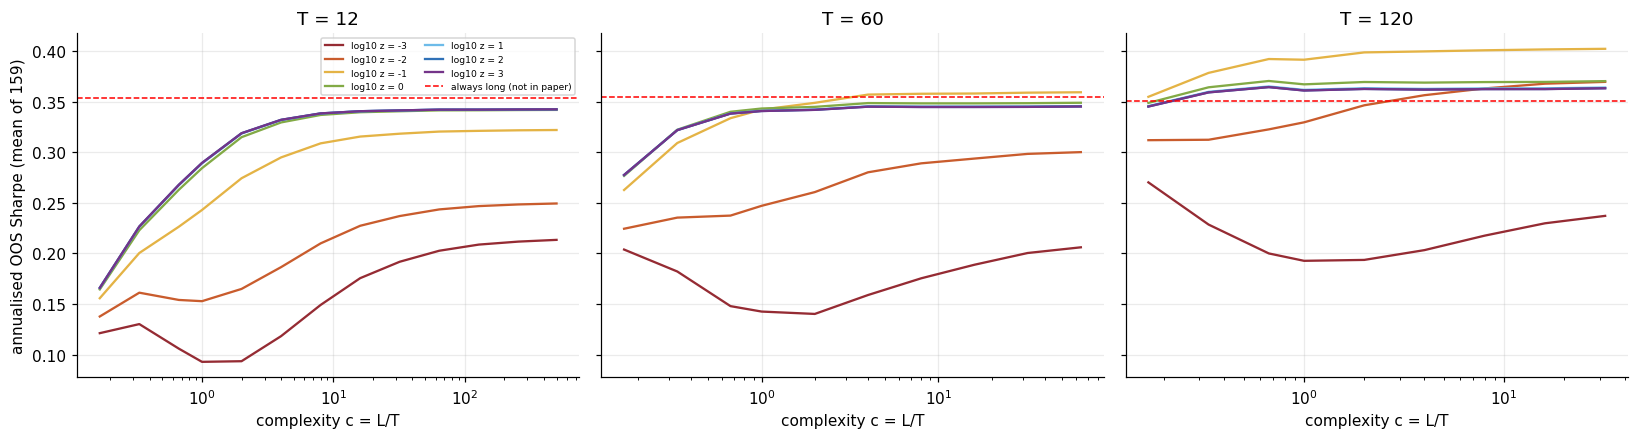

c=0.17    c=1   c=16  c_max  c_max value
T   z                                             
12  1e-3   0.121  0.093  0.176  0.213        500.0
    1e-1   0.156  0.243  0.315  0.322        500.0
    1e+3   0.166  0.289  0.340  0.342        500.0
60  1e-3   0.204  0.143  0.189  0.206         64.0
    1e-1   0.263  0.342  0.358  0.359         64.0
    1e+3   0.277  0.341  0.345  0.345         64.0
120 1e-3   0.270  0.193  0.230  0.237         32.0
    1e-1   0.355  0.391  0.401  0.402         32.0
    1e+3   0.345  0.361  0.362  0.363         32.0

T=12: Sharpe at c_max minus c_min (z=1e3) +0.176 (s.e. 0.009, 96% of factors positive); always long 0.353, trailing 0.338
T=60: Sharpe at c_max minus c_min (z=1e3) +0.068 (s.e. 0.005, 86% of factors positive); always long 0.354, trailing 0.309
T=120: Sharpe at c_max minus c_min (z=1e3) +0.018 (s.e. 0.002, 75% of factors positive); always long 0.351, trailing 0.303


In [14]:
D = {T: np.load(FIG / f"curves_T{T}.npz") for T in (12, 60, 120)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.1), sharey=True)
for a, T in zip(ax, D):
    dT = D[T]; sr = dT["SR"].mean(0)
    for j, zz in enumerate(dT["z"]):
        a.plot(dT["c"], sr[:, j], color=PAPER_COLORS[j], label=zlabel(zz))
    a.axhline(dT["long"].mean(), color="r", ls="--", lw=1, label="always long (not in paper)")
    a.set_xscale("log"); a.set_title(f"T = {T}"); a.set_xlabel("complexity c = L/T")
ax[0].set_ylabel("annualised OOS Sharpe (mean of 159)"); ax[0].legend(fontsize=6, ncol=2)
fig.tight_layout(); plt.show()

rows = []
for T, dT in D.items():
    s_ = dT["SR"].mean(0); cT = dT["c"]
    for j in (0, 2, 6):
        rows.append({"T": T, "z": f"1e{int(np.log10(dT['z'][j])):+d}", f"c={cT[0]:.2f}": s_[0, j], "c=1": s_[int(np.argmin(abs(cT - 1))), j],
                     "c=16": s_[int(np.argmin(abs(cT - 16))), j], "c_max": s_[-1, j], "c_max value": cT[-1]})
display(pd.DataFrame(rows).set_index(["T", "z"]).round(3))
for T, dT in D.items():
    g = dT["SR"][:, -1, 6] - dT["SR"][:, 0, 6]
    print(f"T={T}: Sharpe at c_max minus c_min (z=1e3) {g.mean():+.3f} (s.e. {g.std(ddof=1)/np.sqrt(len(g)):.3f}, {np.mean(g > 0):.0%} of factors positive); always long {dT['long'].mean():.3f}, trailing {dT['trail'].mean():.3f}")

**Reading it.** With a large ridge the curve rises, but much less than at $T=12$: +0.068 at $T=60$ (1.24×) and +0.018 at $T=120$ (1.05×); the Welch-Goyal version +0.069 and +0.030. The paper's Figure 5 shows a monotone rise at both windows: same direction, smaller size, and never clearly above always long (−0.009 and +0.013, s.e. 0.013 and 0.012). Caveat: at a fixed $c=1/6$ the longer windows already have more features (10 and 20, against 2 at $T=12$), so the low-complexity end is not comparable across windows. At $T=120$ an intermediate ridge ($z=10^{-1}$) reaches 0.40, above always long (0.35), but that $z$ was picked by looking at the out-of-sample grid, so it is not evidence of timing skill.

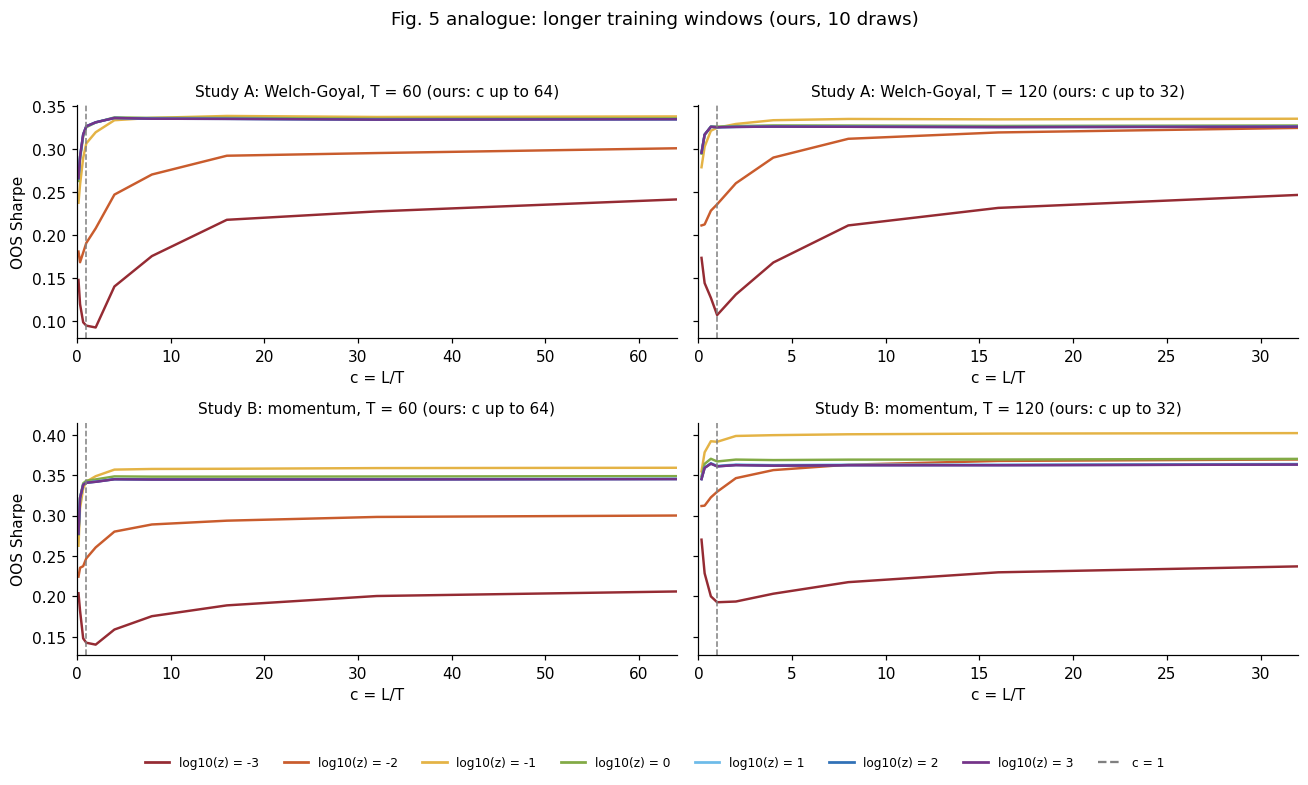

In [15]:
# Fig. 5 on the paper's axes: linear c. Rows: Study A (Welch-Goyal) and Study B (momentum); columns: T = 60 and T = 120.
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharey="row")
for r_, (name, tag) in enumerate([("Study A: Welch-Goyal", "_wg"), ("Study B: momentum", "")]):
    for k_, T in enumerate((60, 120)):
        dT = np.load(FIG / f"curves_T{T}{tag}.npz"); sr = dT["SR"].mean(0)
        for j in range(7):
            ax[r_, k_].plot(dT["c"], sr[:, j], color=PAPER_COLORS[j], lw=1.6)
        ax[r_, k_].axvline(1, color="gray", ls="--", lw=1); ax[r_, k_].set_xlim(0, dT["c"][-1]); ax[r_, k_].grid(False)
        ax[r_, k_].set_title(f"{name}, T = {T} (ours: c up to {dT['c'][-1]:.0f})", fontsize=10); ax[r_, k_].set_xlabel("c = L/T")
    ax[r_, 0].set_ylabel("OOS Sharpe")
zlegend(fig); fig.suptitle("Fig. 5 analogue: longer training windows (ours, 10 draws)", y=1.0)
fig.tight_layout(rect=[0, 0.08, 1, 0.97]); plt.show()

## 5. Feature scaling: why we use $1/\sqrt{L}$

The paper divides the features by $\sqrt P$ (eq. 37) but does not say which $P$: the model's width $L$, the $7p$ weights, or something else. **We use $1/\sqrt L$**, the number of features in the model being fitted. This is the standard random-feature normalisation (Rahimi & Recht 2007, Algorithm 1: $\sqrt{2/D}$ with $D$ the number of features; Sutherland & Schneider 2015, eq. 1): it makes $FF'/L$ converge to the kernel at every model size, and it makes the effective ridge independent of $L$. It differs from theirs only by a constant $\sqrt2$, which rescales $z$ by a factor of 2.

A consequence: with $1/\sqrt L$ every curve with $z\ge10$ coincides and is flat, whereas in the paper's Figure 3 (momentum panel) the $z=10$ and $z=100$ curves sit below $z=10^3$ at high complexity (about 0.20 and 0.25 against 0.30 at $c=1000$) and the curves for $z=1\ldots100$ fall with $c$ after a peak near $c=3$-$10$. As a check on this, we try a constant normalisation $S=F/\sqrt\kappa$, which lets the effective ridge shrink as $L$ grows and so makes curves fall. `experiments/scaling_check.py` runs $\kappa\in\{1,\,T,\,7p\}$ on all 159 factors (10 seeds).

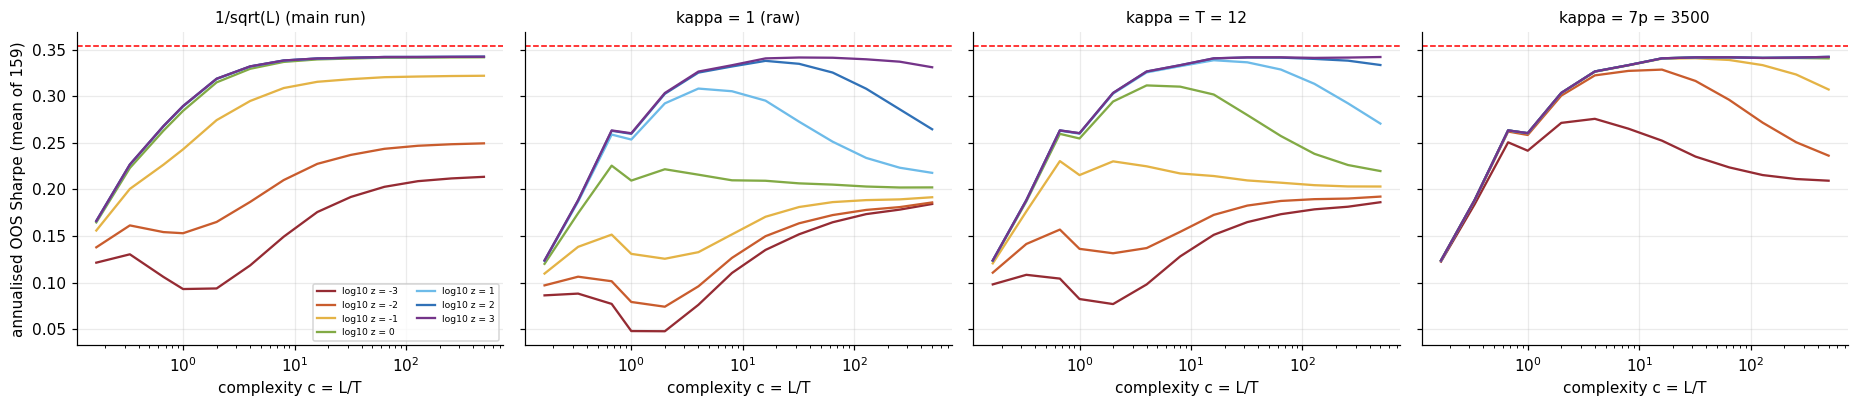

,"paper (c=1000, by eye)",1/sqrt(L),kappa = 1 (raw),kappa = T = 12,kappa = 7p = 3500
z=1e+3,0.30,0.342,0.331,0.342,0.342
z=1e+2,0.25,0.342,0.264,0.333,0.342
z=1e+1,0.20,0.342,0.218,0.271,0.342
z=1e+0,0.17,0.342,0.202,0.220,0.341
z=1e-1,0.17,0.322,0.192,0.203,0.307
z=1e-2,0.16,0.249,0.186,0.192,0.236
z=1e-3,0.15,0.213,0.184,0.186,0.209


OOS R^2 at c = 500 (paper, by eye at c = 1000: about -0.45 at z=1e-3, -0.18 at z=10, +0.04 at z=1e3):


,1/sqrt(L),kappa = 1 (raw),kappa = T = 12,kappa = 7p = 3500
z=1e+3,-0.019,-0.013,-0.013,-0.019
z=1e+2,-0.019,-0.086,-0.011,-0.019
z=1e+1,-0.017,-0.172,-0.078,-0.017
z=1e+0,-0.010,-0.206,-0.167,-0.008
z=1e-1,-0.022,-0.234,-0.204,-0.036
z=1e-2,-0.109,-0.264,-0.231,-0.132
z=1e-3,-0.181,-0.281,-0.262,-0.191


In [16]:
sc = np.load(FIG / "scaling_check.npz"); main = np.load(FIG / "curves_T12.npz")
labels = [str(k) for k in sc["kappas"]]
c_sc, z_sc = sc["c"], sc["z"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
panels = [("1/sqrt(L) (main run)", main["SR"].mean(0), main["c"])] + [(f"kappa = {labels[j]}", sc[f"SR_{j}"].mean(0), c_sc) for j in range(3)]
for a, (title, sr, cc) in zip(ax, panels):
    for q, zz in enumerate(z_sc):
        a.plot(cc, sr[:, q], color=PAPER_COLORS[q], label=zlabel(zz))
    a.axhline(float(main["long"].mean()), color="r", ls="--", lw=1)
    a.set_xscale("log"); a.set_title(title, fontsize=10); a.set_xlabel("complexity c = L/T")
ax[0].set_ylabel("annualised OOS Sharpe (mean of 159)"); ax[0].legend(fontsize=6, ncol=2)
fig.tight_layout(); plt.show()

paper_c1000 = {1e3: 0.30, 1e2: 0.25, 1e1: 0.20, 1e0: 0.17, 1e-1: 0.17, 1e-2: 0.16, 1e-3: 0.15}   # read off Fig. 3B by eye
tab = pd.DataFrame({"paper (c=1000, by eye)": [paper_c1000[float(zz)] for zz in z_sc],
                    "1/sqrt(L)": main["SR"].mean(0)[-1],
                    **{f"kappa = {labels[j]}": sc[f"SR_{j}"].mean(0)[-1] for j in range(3)}},
                   index=[f"z=1e{int(np.log10(zz)):+d}" for zz in z_sc])
display(tab.iloc[::-1].round(3))
r2tab = pd.DataFrame({"1/sqrt(L)": main["R2"].mean(0)[-1], **{f"kappa = {labels[j]}": sc[f"R2_{j}"].mean(0)[-1] for j in range(3)}},
                     index=[f"z=1e{int(np.log10(zz)):+d}" for zz in z_sc])
print("OOS R^2 at c = 500 (paper, by eye at c = 1000: about -0.45 at z=1e-3, -0.18 at z=10, +0.04 at z=1e3):")
display(r2tab.iloc[::-1].round(3))

In [17]:
bcols = {"1/sqrt(L) (main)": np.sqrt(main["B2"].mean(0))[:, 0]}
bcols.update({f"kappa = {labels[j]}": np.sqrt(sc[f"B2_{j}"].mean(0))[:, 0] for j in range(3)})
display(pd.DataFrame(bcols, index=pd.Index(c_sc.round(2), name="c")).T.iloc[:, [0, 2, 3, 4, 5, 7, 8, 10, 12]].round(2))
print("||beta|| at z = 1e-3, mean over 159 factors (paper's Fig. 1: rises to a peak near c = 1-2, then falls)")

c,0.17,0.67,1.00,2.00,4.00,16.00,32.00,128.00,500.00
1/sqrt(L) (main),2.09,6.71,8.61,9.57,8.98,8.11,7.95,7.83,7.81
kappa = 1 (raw),1.40,4.67,6.28,4.44,2.12,0.92,0.65,0.33,0.17
kappa = T = 12,3.06,7.26,8.88,8.13,5.39,2.60,1.87,1.00,0.54
kappa = 7p = 3500,5.05,9.08,10.48,12.51,14.71,16.32,15.20,10.57,6.31


||beta|| at z = 1e-3, mean over 159 factors (paper's Fig. 1: rises to a peak near c = 1-2, then falls)


**Reading it.**
* With the **literal eq. 37 features**, $\kappa=1$ (unscaled) reproduces the paper's $z$-dependence closely: 0.33, 0.26, 0.22, 0.20, 0.19, 0.19, 0.18 for $z=10^3\ldots10^{-3}$ against ≈ 0.30, 0.25, 0.20, 0.17, 0.17, 0.16, 0.15. $\kappa=T$ is the next closest; $1/\sqrt L$ (main) and $\kappa=7p$ give coinciding curves for $z\ge1$. (Under the eq. 36 kernel $\kappa=1$ gave only 0.030 at $z=10^{-3}$, so this agreement depends on the kernel convention.)
* $R^2$ at $z=10^{-3}$, $c=500$: $\kappa=1$ −0.28, $\kappa=T$ −0.26, $1/\sqrt L$ −0.18, paper ≈ −0.45.
* The paper's $\|\hat\beta\|$ **falls** with $c$ past 1–2 (Lemma 1). Under $\kappa=1$ or $T$ so does mine (table above: at $z=10^{-3}$ it peaks at $c=1$, 6.3 or 8.9, and falls to 0.16 or 0.52 at $c=500$), while under $1/\sqrt L$ it peaks at 9.6 ($c=2$) and plateaus at 7.8, and under $\kappa=7p$ it peaks late (16.3 at $c=16$).
* The paper's expected return at $z=10^3$ is 0.010 against our 0.000 under $1/\sqrt L$: its $z$ axis sits about three decades above mine.
* **The main figures use $1/\sqrt L$** (kernel-consistent). The paper does not state its normalisation, so $\kappa=1$ is a candidate explanation of the mismatch, not a finding, and the main figures were not rerun with it. What does not depend on it: the best attainable Sharpe is about 0.342 under every one of them, so the no-edge-over-always-long and placebo conclusions stand.

## 6. Beyond the paper: baselines, placebo, exact kernel

**Baselines the paper does not report:** *always long* the volatility-scaled factor, $\hat\pi_t=1$; *trailing mean*, $\hat\pi_t=\frac1T\sum_{\tau<t}y_\tau$; *linear ridge* on the two raw signals.

In [18]:
d = D[12]; n = len(d["SR"]); cmax = d["SR"][:, -1, 6]
def stat(x): return f"{x.mean():+.3f} (s.e. {x.std(ddof=1) / np.sqrt(n):.3f}; {np.mean(x > 0):.0%} of factors > 0)"
display(pd.Series({"VoC model, c=500, z=1e3": cmax.mean(), "always long": d["long"].mean(), "trailing 12m mean": d["trail"].mean(),
                   "linear ridge (z=1e-3)": d["linear"].mean(0)[0], "linear ridge (z=1e3)": d["linear"].mean(0)[-1]}, name="annualised Sharpe").round(3).to_frame())
print("model minus always long      :", stat(cmax - d["long"]))
print("model minus trailing 12m mean:", stat(cmax - d["trail"]))
ff = [list(map(str, d["names"])).index(f) for f in FACTORS]; rest = [i for i in range(n) if i not in ff]
print(f"6 French factors: {cmax[ff].mean():.3f} (always long {d['long'][ff].mean():.3f});  153 JKP factors: {cmax[rest].mean():.3f} (always long {d['long'][rest].mean():.3f})")

,annualised Sharpe
"VoC model, c=500, z=1e3",0.342
always long,0.353
trailing 12m mean,0.338
linear ridge (z=1e-3),0.143
linear ridge (z=1e3),0.106


model minus always long      : -0.011 (s.e. 0.017; 45% of factors > 0)
model minus trailing 12m mean: +0.004 (s.e. 0.003; 55% of factors > 0)
6 French factors: 0.410 (always long 0.461);  153 JKP factors: 0.340 (always long 0.349)


**Placebo.** If the curve reflects learned predictability, destroying the link between $X_t$ and the return that follows should flatten it. We permute the signal rows in time (same distribution, no link to the next return), 20 times, keeping the targets in their true order. Anything that uses only the factor's own past returns, such as the unconditional premium or a trailing mean, survives; only the signal→return mapping is destroyed. The placebo's feature draws cycle through the same 100 seeds as the real run (5 draws per shuffle).

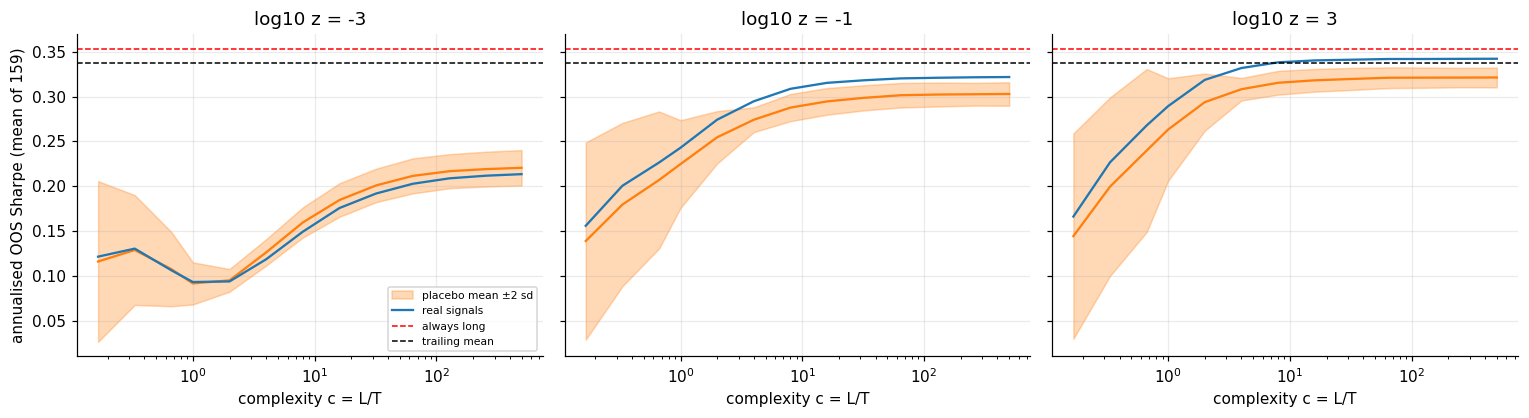

,real,placebo mean,placebo sd,real - placebo
c (z=1e3),,,,
0.17,0.166,0.144,0.057,0.022
1.00,0.289,0.263,0.029,0.026
16.00,0.340,0.318,0.006,0.022
500.00,0.342,0.321,0.006,0.021


Sharpe gain from c=0.17 to c=500 at z=1e3:  real +0.176;  placebo +0.177 (sd 0.058)


In [19]:
p = np.load(FIG / "placebo.npz")
c, z, real, plc = p["c"], p["z"], p["real"], p["placebo"]
pm, ps_ = plc.mean(0), plc.std(0, ddof=1)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for a, k in zip(ax, [0, 2, 6]):
    a.fill_between(c, pm[:, k] - 2 * ps_[:, k], pm[:, k] + 2 * ps_[:, k], color="tab:orange", alpha=.3, label="placebo mean ±2 sd")
    a.plot(c, pm[:, k], color="tab:orange"); a.plot(c, real[:, k], color="tab:blue", label="real signals")
    a.axhline(float(p["long"]), color="r", ls="--", lw=1, label="always long"); a.axhline(float(p["trail"]), color="k", ls="--", lw=1, label="trailing mean")
    a.set_xscale("log"); a.set_title(zlabel(z[k])); a.set_xlabel("complexity c = L/T")
ax[0].set_ylabel("annualised OOS Sharpe (mean of 159)"); ax[0].legend(fontsize=7); fig.tight_layout(); plt.show()
pick = nearest(c, [1 / 6, 1, 16, 500]); k = 6
display(pd.DataFrame({"real": real[pick, k], "placebo mean": pm[pick, k], "placebo sd": ps_[pick, k],
                      "real - placebo": real[pick, k] - pm[pick, k]}, index=pd.Index(c[pick].round(2), name="c (z=1e3)")).round(3))
g_real = real[-1, k] - real[0, k]; g_plc = plc[:, -1, k] - plc[:, 0, k]
print(f"Sharpe gain from c={c[0]:.2f} to c={c[-1]:.0f} at z=1e3:  real {g_real:+.3f};  placebo {g_plc.mean():+.3f} (sd {g_plc.std(ddof=1):.3f})")

**Placebo at the longer windows.** The same test at $T=60$ and $T=120$ (10 shuffles each; the shuffles cycle through the 10 seeds of the real run).

In [20]:
rows = []
for T in (60, 120):
    pT = np.load(FIG / f"placebo_T{T}.npz"); cT = pT["c"]; k = 6
    idx = [0, int(np.argmin(abs(cT - 1))), int(np.argmin(abs(cT - 16))), len(cT) - 1]
    m_, s_ = pT["placebo"][:, :, k].mean(0), pT["placebo"][:, :, k].std(0, ddof=1)
    for i in idx:
        rows.append({"T": T, "c": round(float(cT[i]), 2), "real": pT["real"][i, k], "placebo mean": m_[i], "placebo sd": s_[i],
                     "real - placebo": pT["real"][i, k] - m_[i], "sd units": (pT["real"][i, k] - m_[i]) / s_[i]})
display(pd.DataFrame(rows).set_index(["T", "c"]).round(3))
for T in (60, 120):
    pT = np.load(FIG / f"placebo_T{T}.npz"); gp = pT["placebo"][:, -1, 6] - pT["placebo"][:, 0, 6]
    print(f"T={T}: Sharpe gain c_min -> c_max at z=1e3: real {pT['real'][-1, 6] - pT['real'][0, 6]:+.3f}; placebo {gp.mean():+.3f}; always long {float(pT['long']):.3f}, trailing {float(pT['trail']):.3f}")

real  placebo mean  placebo sd  real - placebo  sd units
T   c                                                               
60  0.17   0.277         0.220       0.088           0.057     0.652
    1.00   0.341         0.289       0.013           0.051     3.912
    16.00  0.345         0.297       0.005           0.047     9.825
    64.00  0.345         0.297       0.005           0.048     9.221
120 0.17   0.345         0.269       0.037           0.076     2.048
    1.00   0.361         0.291       0.008           0.070     8.512
    16.00  0.362         0.293       0.006           0.069    12.257
    32.00  0.363         0.293       0.006           0.070    12.729

T=60: Sharpe gain c_min -> c_max at z=1e3: real +0.068; placebo +0.076; always long 0.354, trailing 0.309
T=120: Sharpe gain c_min -> c_max at z=1e3: real +0.018; placebo +0.023; always long 0.351, trailing 0.303


At $T=60$ and $120$ the rise with $c$ is again as large for the placebo as for the real signals. But the real signals now beat the placebo by far more than at $T=12$ (+0.048 and +0.070 against +0.021, 9–13 placebo sd): with 60–120 months of training the signals carry information beyond the factor's own average return, even though the Sharpe does not rise with complexity.

**Exact kernel.** As $L\to\infty$ the random-feature model converges to exact kernel ridge with the mixture kernel (no sampling). If the placebo's rise is just the sampled kernel converging, the exact-kernel placebo should equal the $c=500$ random-feature placebo.

In [21]:
e = np.load(FIG / "exact_kernel.npz")
cols = [f"1e{int(np.log10(zz)):+d}" for zz in e["z"]]
display(pd.DataFrame({"exact kernel, real": e["real"], "RFF c=500, real": p["real"][-1],
                      "exact kernel, placebo": e["placebo"].mean(0), "RFF c=500, placebo": p["placebo"].mean(0)[-1],
                      "RFF c=0.17, placebo": p["placebo"].mean(0)[0], "RFF c=0.17, real": p["real"][0]}, index=cols).T.round(3))

,1e-3,1e-2,1e-1,1e+0,1e+1,1e+2,1e+3
"exact kernel, real",0.215,0.251,0.322,0.342,0.343,0.343,0.343
"RFF c=500, real",0.213,0.249,0.322,0.342,0.342,0.342,0.342
"exact kernel, placebo",0.222,0.248,0.303,0.320,0.321,0.321,0.321
"RFF c=500, placebo",0.221,0.247,0.303,0.320,0.321,0.321,0.321
"RFF c=0.17, placebo",0.116,0.127,0.139,0.144,0.144,0.144,0.144
"RFF c=0.17, real",0.121,0.138,0.156,0.165,0.166,0.166,0.166


**Reading it.**
* **No timing edge**: the best model is 0.342 and always long is 0.353; the difference is well inside its standard error. It is about 0.004 above a plain trailing mean (0.338). The six French factors score 0.41 and the 153 JKP factors 0.34, so the French factors are not representative of the 159. The factors are signed using the original publications' findings, so "always long" uses knowledge of which direction worked in the literature that a real-time investor would not have.
* **The rise is the kernel.** The placebo rises by the same amount (+0.177) as the real curve (+0.176). At high complexity the real signals add about +0.02 (≈ 4 placebo sd, across shuffles, descriptive and not a p-value); at $c\le1$ the gap is within seed noise. Exact kernel ridge matches the $c=500$ model to three decimals, for real and shuffled signals.
* **The smallest model is noisy.** At $L=2$ the model is one random (sin, cos) pair, and its Sharpe depends on that draw: in the eq. 36 set (20 seeds) the 159-factor mean ranged from −0.01 to 0.37 (sd 0.135), and the same seed is shared by all factors; with eq. 37 the $c=0.17$ point moved from 0.135 (20 draws) to 0.166 (100 draws). A first version used 5 seeds and reported 0.17 at $c=0.17$ (a "2× rise"); that was a property of those five seeds. Points at $c\ge1$ are stable. The paper averages 100 seeds.

## 7. Paper vs. this replication

| | Paper (Figs 1–5; read off by eye) | Here: momentum signals | Here: Welch–Goyal signals |
|---|---|---|---|
| Sharpe, low complexity, large $z$ | ≈ 0.1 (B), ≈ 0.11 (A) | 0.166 ($c=0.17$) | 0.117 |
| Sharpe, high complexity, large $z$ | ≈ 0.30 (B), ≈ 0.36 (A) | 0.342 | 0.368 |
| Gain low → high $c$, $T=12$ | "a factor of three" | 2.1× | 3.1× |
| Gain low → high $c$, $T=60,120$ | monotone rise (Fig. 5) | +0.068, +0.018 | +0.069, +0.030 |
| No-ridge curve ($z=10^{-3}$) | dip near $c=1$ to ≈ 0.07, then ≈ 0.15 (B); ≈ 0.07 → ≈ 0.32 (A) | 0.121, min 0.093 at $c=1$, 0.213 | 0.079, min 0.079 at $c=1$, 0.305 |
| $z=10,100$ curves (Fig. 3) | below the $z=10^3$ plateau (B) | coincide with $z=10^3$; $\kappa=1$ reproduces them (section 5) | coincide |
| $\|\hat\beta\|$ (Fig. 1) | falls with $c$ past 1 | peaks at $c=2$, plateau 7.8 | plateau 6.1 |
| ER at low $z$ (Fig. 2) | ≈ 0.04 | 0.039 | 0.038 |

The paper's values are read off its figures by eye, and the paper does not say whether Sharpe ratios are annualised (we annualise; its Fig. 2 values for ER and Vol imply annualised Sharpe ratios of about the size in its Fig. 3). The paper's ≈ 0.30 at high complexity is close to the mean Sharpe of the 159 factors in its own Table 1 (0.31).

### What did not work, or did not match
1. The effect for momentum signals is smaller than reported (2.1× vs ≈ 3× at $T=12$, +0.018 to +0.068 at $T=60,120$); the Welch–Goyal panel gives 3.1×. We do not know whether the momentum gap is our signal construction, our feature normalisation, or the sample.
2. No demonstrated timing edge: the best model is −0.011 (momentum) and +0.019 (Welch–Goyal) from always long, s.e. 0.017–0.018. The paper has no baseline that would let one say the model wins.
3. The $z$-dependence of the curves and $\|\hat\beta\|$ do not match the paper's with our $1/\sqrt L$ scaling; unscaled features ($\kappa=1$) fit much better (section 5) but were not used for the main runs. Partly resolved.
4. The double-ascent dip is at $c=1$ on real data, as in the paper, but our simulator does not show it at low ridge (only at large ridge, $t=-2.5$), though $\|\hat\beta\|$ blows up at $c=1$ as predicted. Unresolved.
4b. We switched the main kernel convention from eq. (36) to the literal eq. (37) after seeing which fits the paper better (Appendix B).
5. The rise with $c$ appears without signal information (placebo).
6. Our first 159-factor and placebo runs used different feature seeds and produced a spurious "2× rise" and "+14 sd" gap; corrected (section 6).
7. Not done: futures and Treasuries (proprietary data), 100 seeds at $T=60,120$ (10 used), the seed-averaged position of eq. (39), and $c$ up to 1,000 (500 here).

### Where the paper is ambiguous
* **Feature scaling.** We use $S=F/\sqrt L$. A fixed $1/\sqrt{P_{\rm total}}$ makes "$z=10^{-3}$" not near-ridgeless at small $L$; unscaled features fit the paper's $z$-dependence better (section 5).
* **Welch–Goyal predictors.** Built from Goyal's spreadsheet from the paper's footnote list; `infl` lagged one month, market return = month-$t$ CRSP S&P return, standardised by an expanding RMS over the full history, clipped at ±5, sample to 2020-12.
* **Eq. (36) vs (37).** Taken literally, eq. (37) gives a kernel $e^{-\gamma^2\|\Delta x\|^2/2}$, not eq. (36)'s $e^{-\|\Delta x\|^2/(2\gamma)}$. The main runs use the literal eq. (37); Appendix B compares eq. (36).
* **Eq. (15).** Read literally the sum drops the first 36 observations; we use an expanding window over all data strictly before $t$ with at least 36 observations (differs by ≤ 15% for Mom after 120 observations).
* **$R^2$ denominator.** Eq. (41) is garbled in the PDF, and the text after eq. (52) implies the uncentred $1-\mathrm{MSE}/E[R_{t+1}^2]$. We centre on the sample mean. When $\hat\pi\approx0$ (large $z$) the centred version gives about −0.02 and the uncentred 0.000.
* **Annualisation** of the Sharpe ratio is not stated; We annualise.

Reproduce everything with `python run_all.py` (about 4 hours on 8 cores; `--quick` takes under 3 minutes).

## Appendix A. Simulator (beyond the paper): do the theory's predictions hold when its assumptions hold?

Returns are $R_{t+1}=f(X_t)+\varepsilon$ with unit-variance noise and a small ($\mathrm{Var}f = 0.05$), purely non-linear $f$ (random sinusoids). Predictions from the theory (Kelly et al. 2022):

1. Out-of-sample $R^2$ is negative while Sharpe is positive.
2. With almost no ridge, Sharpe dips toward 0 at $c=1$ (the interpolation boundary), then rises again ("double ascent").
3. With enough ridge, Sharpe is monotone increasing in $c$.
4. (Lemma 1) $\|\hat\beta\|$ decreases in $L$ for $L>T$ in the ridgeless limit.

First a **live** small run to show the pipeline end to end, then the saved 50-dataset result.

In [22]:
# LIVE 3a. one simulated dataset, small settings (a few seconds)
T, p, N = 12, 200, 500   # 14p = 2800 columns >= max L
Xs, ys, _ = simulate_nonlinear(N, d=5, snr=0.05, seed=0)
L_grid = [2, 6, 12, 24, 120, 600, 2400]
z_grid = [1e-3, 1.0, 1e3]
t0 = time.time()
acc = []
for s in range(3):
    F = make_rff(Xs, p=p, seed=1000 + s)
    out = rolling_ridge_voc(F, ys, T, L_grid, z_grid)
    acc.append(summarize(out["pi"], ys[out["t"]])["SR"])
tab = pd.DataFrame(np.mean(acc, axis=0), index=pd.Index(np.array(L_grid) / T, name="c = L/T").round(2),
                   columns=[zlabel(z) for z in z_grid])
print(f"{time.time() - t0:.1f}s; per-period OOS Sharpe on ONE simulated dataset. The s.e. of each entry is about 0.045,")
print("so signs can flip here; the 50-dataset average below is the result that counts.")
display(tab.round(3))

0.4s; per-period OOS Sharpe on ONE simulated dataset. The s.e. of each entry is about 0.045,
so signs can flip here; the 50-dataset average below is the result that counts.


,log10 z = -3,log10 z = 0,log10 z = 3
c = L/T,,,
0.17,0.032,0.033,0.033
0.50,0.021,0.033,0.033
1.00,0.024,0.032,0.033
2.00,-0.005,-0.006,-0.006
10.00,-0.034,-0.025,-0.024
50.00,-0.019,-0.018,-0.017
200.00,0.000,-0.012,-0.013


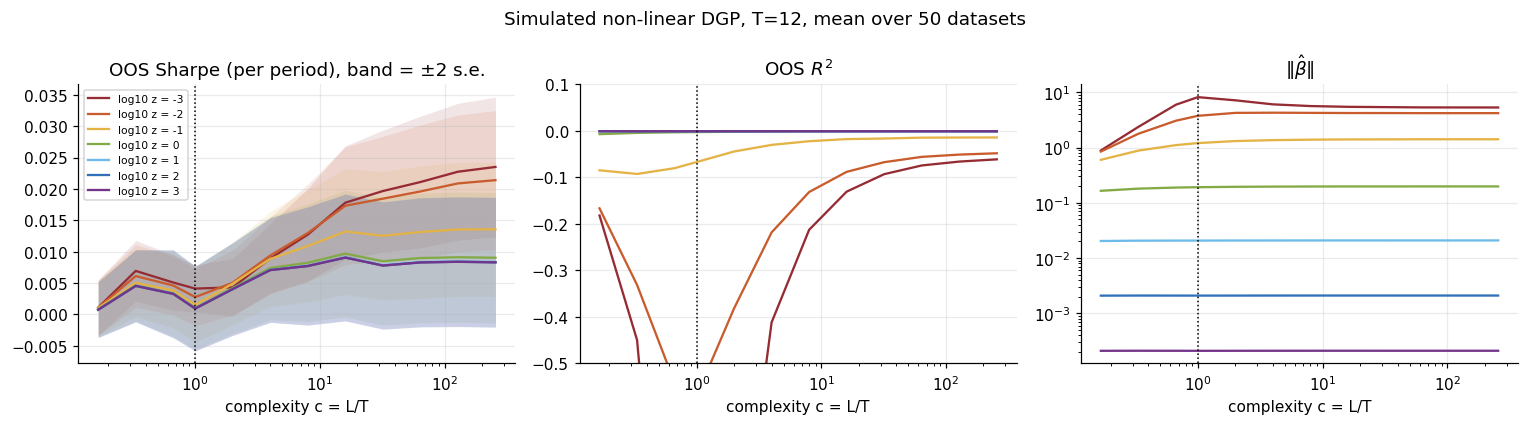

In [23]:
d = np.load(FIG / "sim_theory.npz")
c, z = d["c"], d["z"]
m = {k: d[k].mean(0) for k in ("SR", "R2", "beta2")}
se = d["SR"].std(0, ddof=1) / np.sqrt(d["SR"].shape[0])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
for j, zz in enumerate(z):
    col = PAPER_COLORS[j]
    ax[0].plot(c, m["SR"][:, j], color=col, label=zlabel(zz))
    ax[0].fill_between(c, m["SR"][:, j] - 2 * se[:, j], m["SR"][:, j] + 2 * se[:, j], color=col, alpha=.12, lw=0)
    ax[1].plot(c, m["R2"][:, j], color=col)
    ax[2].plot(c, np.sqrt(m["beta2"][:, j]), color=col)
for a, t in zip(ax, ["OOS Sharpe (per period), band = ±2 s.e.", "OOS $R^2$", r"$\|\hat\beta\|$"]):
    a.set_xscale("log"); a.axvline(1, color="k", ls=":", lw=1); a.set_xlabel("complexity c = L/T"); a.set_title(t)
ax[1].set_ylim(-0.5, 0.1); ax[2].set_yscale("log"); ax[0].legend(fontsize=7)
fig.suptitle(f"Simulated non-linear DGP, T=12, mean over {d['SR'].shape[0]} datasets"); fig.tight_layout(); plt.show()

**Reading it (literal eq. 37 features).** Prediction 1 holds: $R^2$ is about $-2.3$ at $c=1$, $z=10^{-3}$ while Sharpe is positive. Prediction 3 holds beyond $c\approx2$ (Sharpe 0.004 at $c=2$ to 0.024 at $c=256$ at $z=10^{-3}$) but not through $c=1$. Prediction 4 holds ($\|\hat\beta\|$ peaks at $c=1$, 8.2, then falls to 5.3). Prediction 2, the *dip* in Sharpe at $c=1$ without ridge, is **not reproduced**: at $z=10^{-3}$ the paired change from $c=2/3$ to $c=1$ is $-0.0010$ ($t=-0.6$), and at $z=10^{-12}$ $-0.0009$ ($t=-0.3$). A dip does show up at **large** ridge ($t=-2.5$ at $z\ge10$). Without ridge $\|\hat\beta\|$ does explode at $c=1$ (about 4,600 at $z=10^{-12}$), as in the theory. (With the eq. 36 kernel the dip appeared only at $z\le10^{-8}$, weakly.)

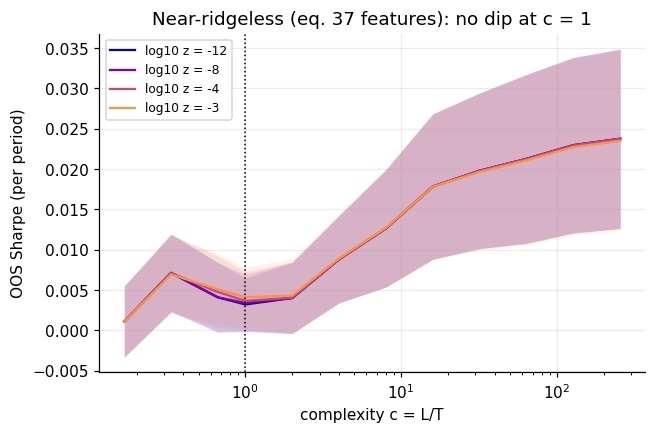

,SR(c=1) - SR(c=2/3),t-stat
log10 z = -12,-0.0009,-0.3377
log10 z = -8,-0.0007,-0.2494
log10 z = -4,-0.0011,-0.5148
log10 z = -3,-0.0010,-0.6264


In [24]:
d2 = np.load(FIG / "sim_theory_z-12_-8_-4_-3.npz")
c2, z2 = d2["c"], d2["z"]
mean2 = d2["SR"].mean(0); se2 = d2["SR"].std(0, ddof=1) / np.sqrt(d2["SR"].shape[0])
fig, ax = plt.subplots(figsize=(6.4, 4))
for j, zz in enumerate(z2):
    col = plt.cm.plasma(j / len(z2))
    ax.plot(c2, mean2[:, j], color=col, label=zlabel(zz))
    ax.fill_between(c2, mean2[:, j] - 2 * se2[:, j], mean2[:, j] + 2 * se2[:, j], color=col, alpha=.12, lw=0)
ax.set_xscale("log"); ax.axvline(1, color="k", ls=":", lw=1)
ax.set_xlabel("complexity c = L/T"); ax.set_ylabel("OOS Sharpe (per period)"); ax.legend(fontsize=8)
ax.set_title("Near-ridgeless (eq. 37 features): no dip at c = 1")
plt.show()
i1, i0 = nearest(c2, [1.0, 2 / 3])
dip = d2["SR"][:, i1, :] - d2["SR"][:, i0, :]
tstat = dip.mean(0) / (dip.std(0, ddof=1) / np.sqrt(len(dip)))
display(pd.DataFrame({"SR(c=1) - SR(c=2/3)": dip.mean(0), "t-stat": tstat}, index=[zlabel(zz) for zz in z2]).round(4))

## Appendix B. Kernel check: what the kernel looks like, and eq. 36 vs eq. 37

Three questions: is the kernel implemented correctly, what does it look like on our signals, and which reading of the paper's eqs. (36)–(37) is right? Eq. (36) says the kernel is $e^{-\|x-y\|^2/(2\gamma)}$; eq. (37) says the features are $\sin(\gamma\,\omega'x),\cos(\gamma\,\omega'x)$ with $\omega\sim N(0,I)$, whose kernel is $e^{-\gamma^2\|x-y\|^2/2}$. These disagree. We first followed eq. (36) (frequencies $\omega/\sqrt\gamma$), then switched the main runs to the literal eq. (37) (frequencies $\gamma\omega$) and reran everything; the eq. (36) runs are kept as `_eq36` files.

In [25]:
print((FIG / "kernel_check.log").read_text())

signals: std per column [0.99 1.03]; pairwise distance quantiles 10/50/90% [0.5  1.41 3.24]

[2] mean off-diagonal kernel value per bandwidth
    gamma           0.1    0.5    1.0    2.0    4.0    8.0   16.0
    eq. 36 (w/sqrt g)   0.076  0.270  0.407  0.557  0.698  0.811  0.891
    eq. 37 (g*w)       0.979  0.698  0.407  0.164  0.050  0.014  0.004

[1] random features (p = 4000 weights per bandwidth block of 7) vs exact mixture kernel, max |error| on 120 points
    convention kernel: 0.0109   (1/sqrt(4000) = 0.0158)
    convention paper : 0.0138   (1/sqrt(4000) = 0.0158)

[3] infinite-ridge exact-kernel position vs trailing mean (T = 12, every 8th factor, first 20)
    eq. 37 literal (main)  real signals     : effective number of past returns used 11.1 of 12; largest weight 0.13 (uniform = 0.08); corr(position, trailing mean) 0.966
    eq. 37 literal (main)  shuffled signals : effective number of past returns used 11.0 of 12; largest weight 0.14 (uniform = 0.08); corr(position, traili

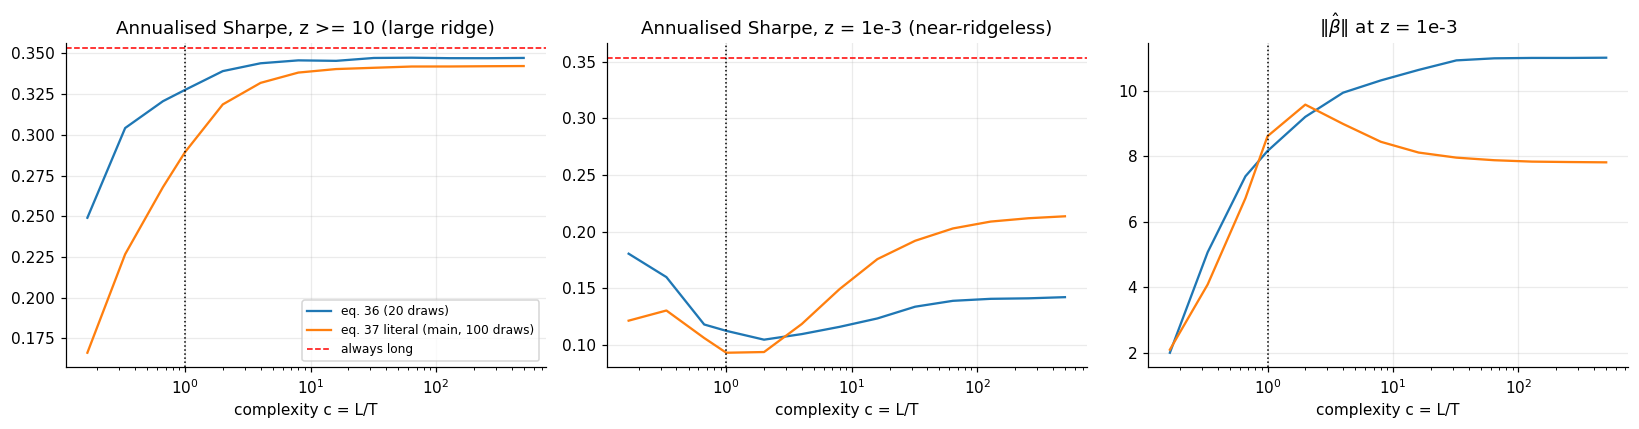

,eq. 36 (20 draws),eq. 37 literal (main),paper (by eye)
"large-z Sharpe, c=0.17",0.249,0.166,0.10
"large-z Sharpe, c=500",0.347,0.342,0.30
gain ratio,1.394,2.061,3.00
z=1e-3: c at minimum,2.000,1.000,1.00
z=1e-3: minimum,0.105,0.093,0.07
z=1e-3: Sharpe at c=500,0.142,0.213,0.15
"ER at z=1e-3, c=500",0.041,0.039,0.04
"Vol at z=1e-3, c=500",0.990,0.630,0.85
"R2 at z=1e-3, c=500",-0.512,-0.181,-0.45
"||beta|| at z=1e-3, c=500",11.004,7.809,NaN


In [26]:
A, B = np.load(FIG / "curves_T12_eq36.npz"), np.load(FIG / "curves_T12.npz")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, j, title in zip(ax[:2], [6, 0], ["z >= 10 (large ridge)", "z = 1e-3 (near-ridgeless)"]):
    a.plot(A["c"], A["SR"].mean(0)[:, j], label="eq. 36 (20 draws)"); a.plot(B["c"], B["SR"].mean(0)[:, j], label="eq. 37 literal (main, 100 draws)")
    a.axhline(float(A["long"].mean()), color="r", ls="--", lw=1, label="always long")
    a.set_xscale("log"); a.set_title(f"Annualised Sharpe, {title}"); a.set_xlabel("complexity c = L/T"); a.axvline(1, color="k", ls=":", lw=1)
ax[0].legend(fontsize=8)
ax[2].plot(A["c"], np.sqrt(A["B2"].mean(0))[:, 0], label="eq. 36"); ax[2].plot(B["c"], np.sqrt(B["B2"].mean(0))[:, 0], label="eq. 37 literal")
ax[2].set_xscale("log"); ax[2].set_title("$\\|\\hat\\beta\\|$ at z = 1e-3"); ax[2].set_xlabel("complexity c = L/T"); ax[2].axvline(1, color="k", ls=":", lw=1)
fig.tight_layout(); plt.show()

def summ(d):
    S_ = d["SR"].mean(0); c_ = d["c"]
    return {"large-z Sharpe, c=0.17": S_[0, 6], "large-z Sharpe, c=500": S_[-1, 6], "gain ratio": S_[-1, 6] / S_[0, 6],
            "z=1e-3: c at minimum": c_[S_[:, 0].argmin()], "z=1e-3: minimum": S_[:, 0].min(), "z=1e-3: Sharpe at c=500": S_[-1, 0],
            "ER at z=1e-3, c=500": d["ER"].mean(0)[-1, 0], "Vol at z=1e-3, c=500": d["Vol"].mean(0)[-1, 0], "R2 at z=1e-3, c=500": d["R2"].mean(0)[-1, 0],
            "||beta|| at z=1e-3, c=500": np.sqrt(d["B2"].mean(0))[-1, 0], "always long": float(d["long"].mean())}
display(pd.DataFrame({"eq. 36 (20 draws)": summ(A), "eq. 37 literal (main)": summ(B),
                      "paper (by eye)": {"large-z Sharpe, c=0.17": 0.1, "large-z Sharpe, c=500": 0.30, "gain ratio": 3.0, "z=1e-3: c at minimum": 1.0,
                                         "z=1e-3: minimum": 0.07, "z=1e-3: Sharpe at c=500": 0.15, "ER at z=1e-3, c=500": 0.04, "Vol at z=1e-3, c=500": 0.85,
                                         "R2 at z=1e-3, c=500": -0.45}}).round(3))

**Reading it.**
* **The implementation is right.** Random features match the exact kernel for both conventions to within $1/\sqrt{4000}$ (first lines above).
* **The placebo is explained.** Under eq. (36) the kernel is nearly constant for the wide bandwidths (mean off-diagonal $K$ = 0.7–0.9 for $\gamma\ge4$), so the infinite-ridge position is a near-uniform average of the past $T$ returns (11.1 of 12 effectively; correlation 0.96 with the trailing mean, for real *and* shuffled signals). Whatever the signals are, the large-$z$ strategy is essentially a trailing mean.
* **The paper's text favours eq. (37) literally.** It says that "when $\gamma$ is close to zero, (8)–(9) is approximately equivalent to a linear model": true for frequencies $\gamma\omega$ (small $\gamma$ = low frequency), false for $\omega/\sqrt\gamma$ (small $\gamma$ = narrow kernel). The literal reading reproduces the paper's Sharpe curve better: the no-ridge dip is at $c=1$ (eq. 36: $c=2$) and the large-$z$ gain is 2.1× (eq. 36: 1.4×; paper ≈ 3×), and the $T=60,120$ rise is larger. It matches Vol worse (0.63 vs ≈ 0.85; eq. 36: 0.99) and $R^2$ better or worse depending on the reading ($-0.18$ against $-0.51$; paper ≈ −0.45, so eq. 36 is closer), $z\ge10$ curves still coincide, and the model still does not beat always long. This choice was made after seeing which version fits the target, so it is not a blind replication; the placebo, exact-kernel, simulator and $T=60,120$ results in this notebook are for the literal eq. (37) and give the same conclusions as under eq. (36).